In [1]:
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import random
import torch.nn.functional as F
import pandas as pd
from sklearn.manifold import TSNE
import numpy as np

from Network import CifarNeural

In [2]:
test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    transform=test_transforms,
    download=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size = 256,
    shuffle = False,
    num_workers = 2,
)

In [3]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

model = CifarNeural()
model.load_state_dict(torch.load("modelCIFAR.pth"))
model = model.to(device)
model.eval()

CifarNeural(
  (stem): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (stage1): Sequential(
    (0): ResBlock(
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu1): ReLU(inplace=True)
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu2): ReLU(inplace=True)
      (dropout): Dropout2d(p=0.1, inplace=False)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (shortcut): Sequential()
    )
    (1): ResBlock(
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu1): ReLU(inplace=True)
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affin

In [4]:
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

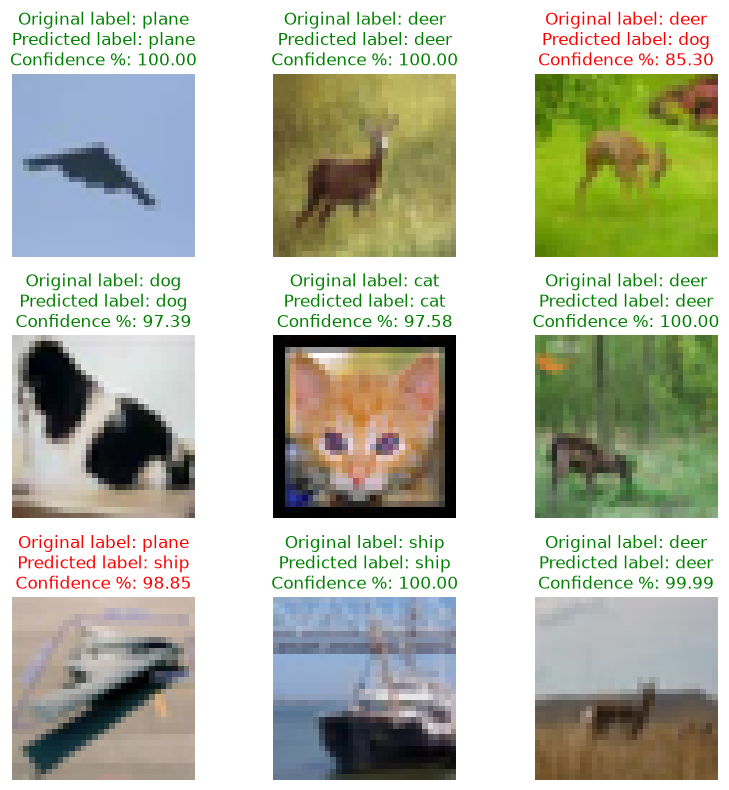

In [5]:
cols, rows = 3, 3

fig, axes = plt.subplots(rows, cols, figsize=(8,8))

axes = axes.flatten()

for i in range(cols*rows):
    random_index = random.randint(0, len(test_dataset) - 1)

    image_tensor, label = test_dataset[random_index]

    image_input = image_tensor.unsqueeze(0).to(device)
    raw_outputs = model(image_input)

    propabilities = F.softmax(raw_outputs, dim=1)
    percent, pred = torch.max(propabilities, dim=1)

    pred = pred.item()

    mean = torch.tensor([0.5, 0.5, 0.5]).view(3,1,1)
    std = torch.tensor([0.5, 0.5, 0.5]).view(3,1,1)

    image_unnorm = image_tensor * std + mean

    image_np = image_unnorm.permute(1, 2, 0).numpy()

    color = 'green' if pred == label else 'red'

    axes[i].imshow(image_np)
    axes[i].set_title(
        f"Original label: {classes[label]}\nPredicted label: {classes[pred]}\nConfidence %: {(percent.item()*100):.2f}",
        color=color
    )
    axes[i].axis('off')

plt.tight_layout()
plt.show()


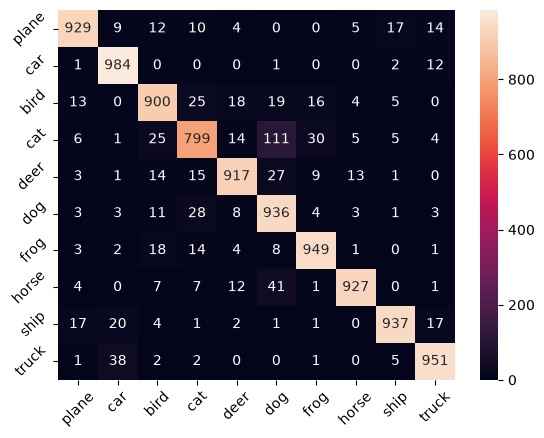

In [6]:
y_true_all = []
y_pred_all = []

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)

        y_pred = torch.argmax(model(X), dim=1)
        y_true = y

        y_true_all.extend(y_true.cpu().numpy())
        y_pred_all.extend(y_pred.cpu().numpy())

cm = confusion_matrix(y_true_all, y_pred_all)

sns.heatmap(cm, annot=True, fmt="d", xticklabels=classes, yticklabels=classes)
plt.yticks(rotation=45)
plt.xticks(rotation=45)
plt.show()

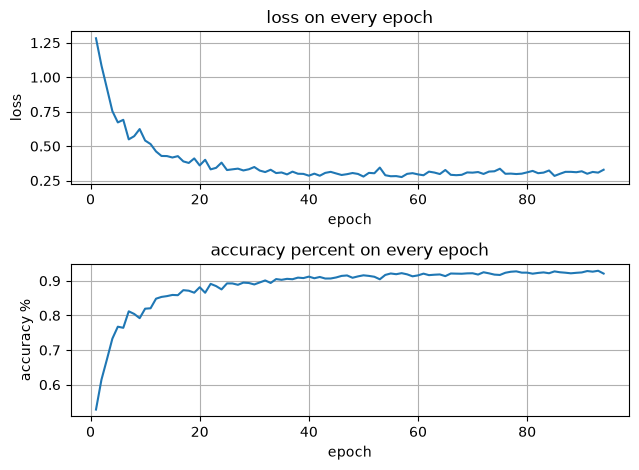

In [7]:
df = pd.read_csv("training_chart_data.csv")

fig, axes = plt.subplots(2, 1)

axes[0].plot(df['epoch'], df['loss'])
axes[0].set_title('loss on every epoch')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].grid()
axes[1].plot(df['epoch'], df['accuracy'])
axes[1].set_title('accuracy percent on every epoch')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('accuracy %')
axes[1].grid()
plt.tight_layout()
plt.show()

In [8]:
all_features = []
all_labels = []

NUM_SAMPLES = 2500
samples_collected = 0

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)

        preds = model(X)

        all_features.append(preds.cpu().numpy())
        all_labels.append(y.numpy())

        samples_collected += X.size(0)
        if samples_collected >= NUM_SAMPLES:
            break

all_features = np.concatenate(all_features, axis=0)[:NUM_SAMPLES]
all_labels = np.concatenate(all_labels, axis=0)[:NUM_SAMPLES]

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
features_2d = tsne.fit_transform(all_features)

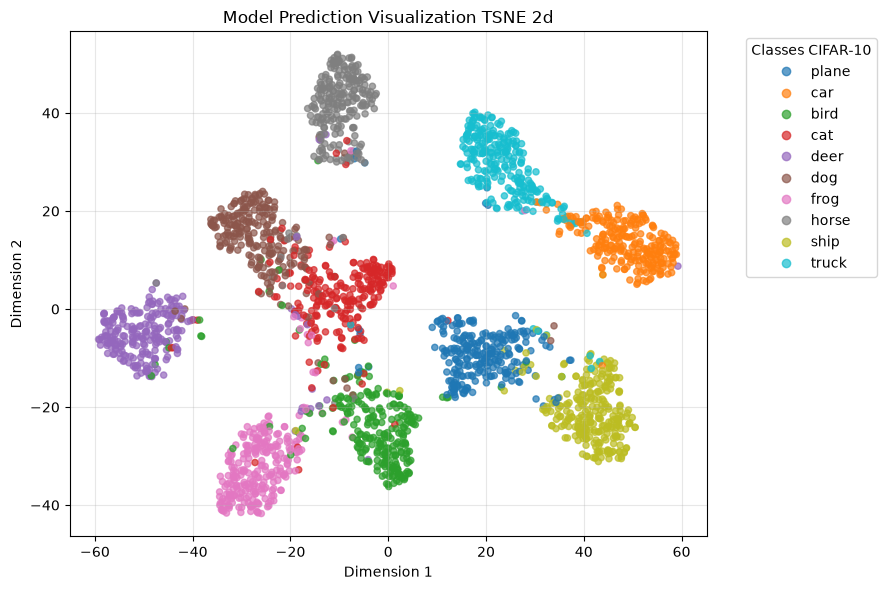

In [9]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    features_2d[:, 0],
    features_2d[:, 1],
    c=all_labels,
    cmap='tab10',
    alpha=0.7,
    s=20
)

plt.legend(handles=scatter.legend_elements()[0], labels=classes, title="Classes CIFAR-10", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title("Model Prediction Visualization TSNE 2d")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()